In [1]:
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

np.set_printoptions(suppress=True, precision=2)

In [2]:
# load dataset
data = np.loadtxt('data_w3_ex1.csv', delimiter=',')
print(data.shape)

x = data[:,0]
y = data[:,1]

print(x.shape)
print(y.shape)

(50, 2)
(50,)
(50,)


In [3]:
# convert x, y to 2D
x = np.expand_dims(x, axis=1)
y = np.expand_dims(y, axis=1)

print(x.shape)
print(y.shape)

(50, 1)
(50, 1)


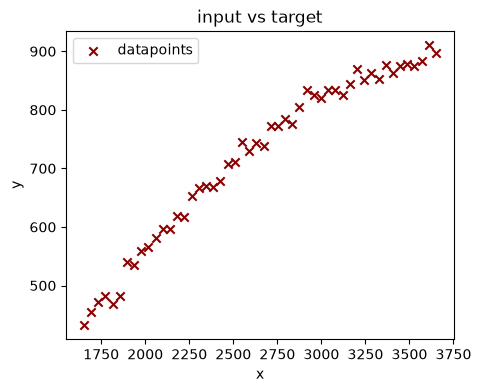

In [4]:
# plot the dataset
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(x, y, c='darkred', marker='x', label='datapoints')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('input vs target')
ax.legend()
plt.show()

In [5]:
# split the dataset into training, cross validation, and test sets.
x_train, x_, y_train, y_ = train_test_split(x, y, test_size=0.4, random_state=1)
x_cv, x_test, y_cv, y_test = train_test_split(x_, y_, test_size=0.5, random_state=1)

del x_, y_

print(f"x_train.shape: {x_train.shape}")
print(f"x_cv.shape: {x_cv.shape}")
print(f"x_test.shape: {x_test.shape}")
print(f"y_train.shape: {y_train.shape}")
print(f"y_cv.shape: {y_cv.shape}")
print(f"y_test.shape: {y_test.shape}")

x_train.shape: (30, 1)
x_cv.shape: (10, 1)
x_test.shape: (10, 1)
y_train.shape: (30, 1)
y_cv.shape: (10, 1)
y_test.shape: (10, 1)


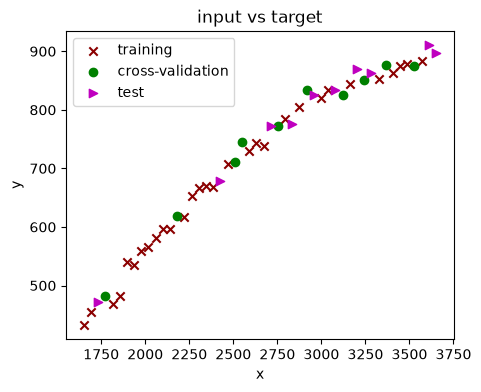

In [6]:
# plot the above dataset
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(x_train, y_train, c='darkred', marker='x', label='training')
ax.scatter(x_cv, y_cv, c='g', marker='o', label='cross-validation')
ax.scatter(x_test, y_test, c='m', marker='>', label='test')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('input vs target')
ax.legend()
plt.show()

In [7]:
# scale our input feature
scaler_linear = StandardScaler()

X_train_scaled = scaler_linear.fit_transform(x_train)

print(f"min X_train_scaled: {np.min(X_train_scaled):.2f}")
print(f"max X_train_scaled: {np.max(X_train_scaled):.2f}")

print(f"\nComputed mean of training set: {scaler_linear.mean_.squeeze():.2f}")
print(f"Computed standard deviation of training set: {scaler_linear.scale_.squeeze():.2f}")

min X_train_scaled: -1.48
max X_train_scaled: 1.85

Computed mean of training set: 2504.06
Computed standard deviation of training set: 574.85


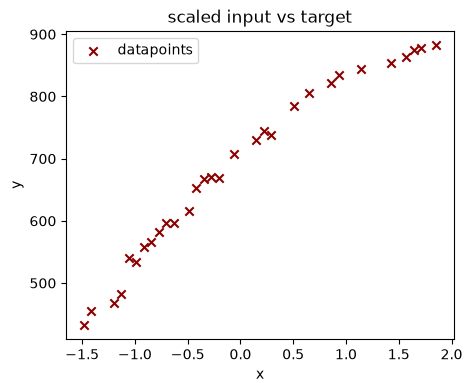

In [8]:
# plot the scaled dataset
# as we can see the scaled input does not have any effect on shape of graph
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(X_train_scaled, y_train, c='darkred', marker='x', label='datapoints')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('scaled input vs target')
ax.legend()
plt.show()

In [9]:
# Train the model
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[136.36]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[681.55]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[5.48]


In [10]:
print(f"linear_model.coef_ (w): {(w := linear_model.coef_.squeeze()):.2f}")
print(f"linear_model.intercept_ (b): {(b := linear_model.intercept_.squeeze()):.2f}")

linear_model.coef_ (w): 136.36
linear_model.intercept_ (b): 681.55


In [11]:
# so our model function becomes
# f(x) = w*x + b
# we can predict our model output by plugging the x input
print(f"model function: f(x) = {w:.2f} x + {b:.2f}")

model function: f(x) = 136.36 x + 681.55


In [12]:
# how to predict
x_new = 2798
x_new = np.array(x_new).reshape(-1,1) # convert to 2D
x_new = scaler_linear.transform(x_new) # scale input as our training set
yhat = linear_model.predict(x_new)
print(f"model prediction (.predict): {yhat.squeeze():.2f}")

# orrr we can do it manually
yhat = w * x_new + b
print(f"model prediction (wx+b): {yhat.squeeze():.2f}")

model prediction (.predict): 751.28
model prediction (wx+b): 751.28


In [13]:
# compute the training error
yhat = linear_model.predict(X_train_scaled)
train_mse = mean_squared_error(y_train, yhat) / 2
print(f"Training MSE: {train_mse}")

Training MSE: 406.19374192533155


In [14]:
# compute the validation error
X_cv_scaled = scaler_linear.transform(x_cv)
yhat = linear_model.predict(X_cv_scaled)
cv_mse = mean_squared_error(y_cv, yhat) / 2
print(f"Cross Validation MSE: {cv_mse:}")

Cross Validation MSE: 551.7789026952216


In [15]:
# now we are adding the polynomial features to our input 
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_mapped = poly.fit_transform(x_train)

print(X_train_mapped[:5])

[[    3324.47 11052096.71]
 [    2344.88  5498450.73]
 [    3487.73 12164293.29]
 [    2630.59  6920013.41]
 [    2589.78  6706937.19]]


In [16]:
# scale our new dataset with polynomial features
scaler_poly = StandardScaler()

X_train_mapped_scaled = scaler_poly.fit_transform(X_train_mapped)

print(X_train_mapped_scaled[:5])

[[ 1.43  1.47]
 [-0.28 -0.36]
 [ 1.71  1.84]
 [ 0.22  0.11]
 [ 0.15  0.04]]


In [17]:
print(np.min(X_train_mapped_scaled, axis=0))
print(np.max(X_train_mapped_scaled, axis=0))

[-1.48 -1.28]
[1.85 2.03]


In [18]:
# train the model
model = LinearRegression()

model.fit(X_train_mapped_scaled, y_train)

#compute the training error
yhat = model.predict(X_train_mapped_scaled)
train_mse = mean_squared_error(y_train, yhat) / 2
print(f"Training MSE: {train_mse}")

# compute the validation error
X_cv_mapped = poly.transform(x_cv)
X_cv_mapped_scaled = scaler_poly.transform(X_cv_mapped)
yhat = model.predict(X_cv_mapped_scaled)
cv_mse = mean_squared_error(y_cv, yhat) / 2
print(f"Cross Validation MSE: {cv_mse}")

Training MSE: 49.111609334025154
Cross Validation MSE: 87.6984121111191


In [19]:
train_mses = []
cv_mses = []
models = []
polys = []
scalers = []

for degree in range(1,11):

    poly = PolynomialFeatures(degree, include_bias=False)
    X_train_mapped = poly.fit_transform(x_train)
    polys.append(poly)

    scaler_poly = StandardScaler()
    X_train_mapped_scaled = scaler_poly.fit_transform(X_train_mapped)
    scalers.append(scaler_poly)

    model = LinearRegression()
    model.fit(X_train_mapped_scaled, y_train)
    models.append(model)

    yhat = model.predict(X_train_mapped_scaled)
    train_mse = mean_squared_error(y_train, yhat) / 2
    train_mses.append(train_mse)

    X_cv_mapped = poly.transform(x_cv)
    X_cv_mapped_scaled = scaler_poly.transform(X_cv_mapped)
    yhat = model.predict(X_cv_mapped_scaled)
    cv_mse = mean_squared_error(y_cv, yhat) / 2
    cv_mses.append(cv_mse)


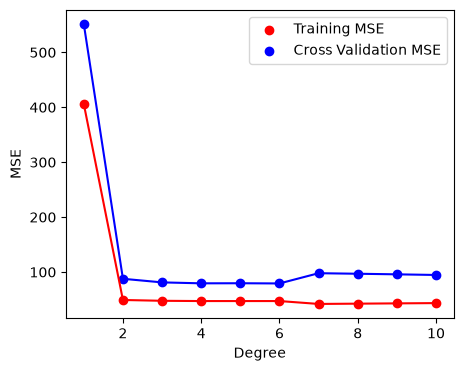

In [20]:
# plot the results
degrees = range(1,11)
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(degrees, train_mses, c='red', marker='o', label='Training MSE')
ax.scatter(degrees, cv_mses, c='blue', marker='o', label='Cross Validation MSE')
ax.plot(degrees, train_mses, c='red')
ax.plot(degrees, cv_mses, c='blue')
ax.set_xlabel('Degree')
ax.set_ylabel('MSE')
ax.legend()
plt.show()

In [21]:
# select the model with the lowest cross validation MSE
degree = np.argmin(cv_mses) + 1
print(f"Lowest CV found in the model with degree = {degree}")

Lowest CV found in the model with degree = 6


In [22]:
# now we've selected the model, let's compute the generalization error or test error for that model

X_test_mapped = polys[degree-1].transform(x_test)
X_test_mapped_scaled = scalers[degree-1].transform(X_test_mapped)

yhat = models[degree-1].predict(X_test_mapped_scaled)
test_mse = mean_squared_error(y_test, yhat) / 2

print(f"Training MSE: {train_mses[degree-1]:.2f}")
print(f"Cross Validation MSE: {cv_mses[degree-1]:.2f}")
print(f"Test MSE: {test_mse:.2f}")

Training MSE: 47.15
Cross Validation MSE: 79.22
Test MSE: 101.50


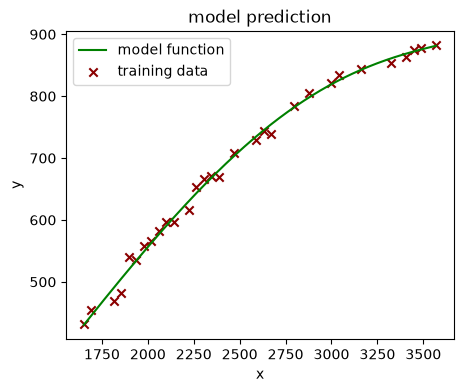

In [23]:
model = models[degree-1]

x_new = np.linspace(np.min(x_train), np.max(x_train), 1000).reshape(-1,1)
x_new_mapped = polys[degree-1].transform(x_new)
x_new_mapped_scaled = scalers[degree-1].transform(x_new_mapped)

yhat = model.predict(x_new_mapped_scaled)

fig, ax = plt.subplots(figsize=(5,4))
ax.plot(x_new, yhat, c='g', label='model function')
ax.scatter(x_train, y_train, c='darkred', marker='x', label='training data')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('model prediction')
ax.legend()
plt.show()